# Assignment 4: Cats and Dogs with Convolutional Neural Networks
**Hazem Daw | Group J4132**  
Machine Learning Technologies, ITMO University, 2026

This completes the supplied CNN and transfer-learning exercise, including the optional
contest. All numbers below come from actual GPU runs. The training engine lives in
`train.py`; the model definitions live in `models.py`. This notebook explains the method,
displays the implementations, and reproduces the analysis from saved outputs.

**Contest eligibility:** only the residual CNN marked **from scratch** is an entry for
Part 3. VGG16 and ResNet18 use ImageNet weights for Part 2 and are ineligible for the contest.
The automatic 5A award depends on the class ranking, which is not available here.

In [1]:
from pathlib import Path
import json, inspect
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage
from torch import nn
from torchvision import models
from models import CNNModel, TransferModel, ScratchResNet
from train import train_run, preprocessing, remove_training_duplicates
from inference import load_classifier, predict_image
ROOT = Path.cwd()
RUN_TRAINING = False  # True repeats the measured runs; False reviews saved results.
if RUN_TRAINING:
    import subprocess, sys
    subprocess.run([sys.executable, 'run_all.py'], check=True)
assert (ROOT / 'results/comparison.csv').exists(), 'Run from the repository folder.'
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
comparison = pd.read_csv(ROOT / 'results/comparison.csv')

PyTorch: 2.11.0+cu128
CUDA available: True


## 1. Data, checks and evaluation protocol
The original course archive has 20,000 training, 2,490 validation and 2,500 test images.
The balanced test set gives a constant-class baseline of 50% accuracy.
It contains 24,990 images, not the 25,000 mentioned in the example notebook: validation
has 1,240 cats and 1,250 dogs. No unreadable image was silently skipped.

SHA-256 hashes of both files and decoded RGB pixels are recorded in `results/data_manifest.csv`.
Three duplicate groups cross split boundaries. Their training copies are excluded;
two redundant copies within training are also excluded, leaving **19,995 training images**.
The supplied validation and test splits remain intact. Two test dog images are identical,
so the binomial confidence intervals are descriptive approximations, not exact independent-sample guarantees.

ImageFolder maps **cats = 0, dogs = 1**. All networks return logits. `BCEWithLogitsLoss`
applies the stable sigmoid/BCE combination; adding a sigmoid in the model would apply it twice.
A logit of zero corresponds to the fixed probability threshold 0.5.

Only training images update weights. Minimum validation BCE selects the epoch. The test
set is evaluated after architecture, training budget, checkpoint and flip-augmentation
choices have been fixed. Audit hashing does not use image labels for model selection.

,Images
test/cats,1250
test/dogs,1250
train/cats,10000
train/dogs,10000
val/cats,1240
val/dogs,1250


Cross-split duplicate groups: 3


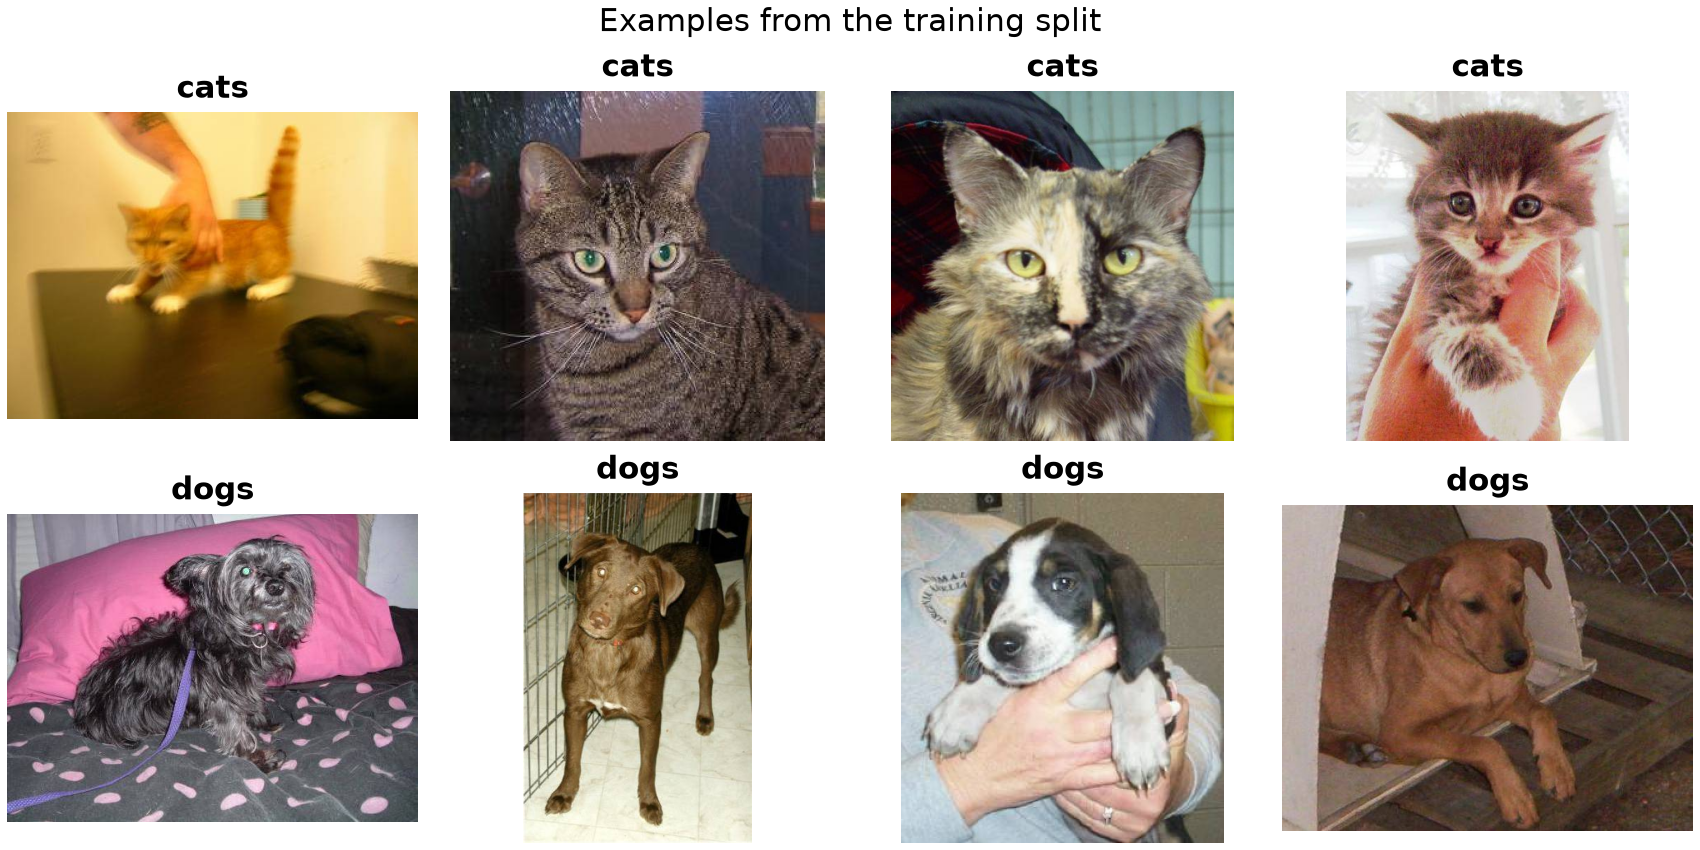

def remove_training_duplicates(dataset, data_root):
    audit_path = ROOT / 'results/data_audit.json'
    if not audit_path.exists():
        raise FileNotFoundError('Run prepare_data.py before training; the duplicate audit is required.')
    audit = json.loads(audit_path.read_text())
    excluded = set()
    for group in audit['duplicate_groups']:
        training = sorted(p for p in group if p.startswith('train/'))
        has_evaluation = any(not p.startswith('train/') for p in group)
        excluded.update(training if has_evaluation else training[1:])
    dataset.samples = [(p, y) for p, y in dataset.samples
                       if Path(p).relative_to(data_root).as_posix() not in excluded]
    dataset.imgs = dataset.samples
    dataset.targets = [y for _, y in dataset.samples]
    return sorted(excluded)



In [2]:
audit = json.loads((ROOT / 'results/data_audit.json').read_text())
display(pd.Series(audit['counts'], name='Images').to_frame())
print('Cross-split duplicate groups:', len(audit['cross_split_duplicates']))
display(DisplayImage(filename=str(ROOT/'figures/training_examples.png')))
print(inspect.getsource(remove_training_duplicates))

## 2. Part 1: the required three-layer CNN
The baseline follows the supplied architecture: 16, 32 and 64 convolutional channels,
3x3 kernels, ReLU and 2x2 max pooling after each convolution. At 150x150 input the spatial
sizes are 150 -> 75 -> 37 -> 18. Flattening feeds 64 hidden units, dropout 0.5 and one logit.
Pixels are scaled to [0,1]. AdamW with zero weight decay is equivalent here to Adam;
the initial learning rate is 0.001.

In [3]:
class CNNModel(nn.Module):
    """The exact three-convolution, 150 x 150 course baseline."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 18 * 18, 64),
                                  nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, 1))

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

In [4]:
model = CNNModel()
print('Output shape:', tuple(model(torch.zeros(2,3,150,150)).shape))
print('Parameters:', sum(p.numel() for p in model.parameters()))
del model

Output shape: (2,)
Parameters: 1350817


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
0,1,0.656297,0.615554,0.605903,0.676707,0.001,41.555251
1,2,0.581796,0.697524,0.540108,0.729317,0.001,22.093824
2,3,0.531550,0.737834,0.509933,0.748996,0.001,17.725325
3,4,0.492434,0.762341,0.488095,0.766265,0.001,22.313119
4,5,0.458515,0.787197,0.463726,0.786345,0.001,20.089266
5,6,0.421323,0.806902,0.431596,0.804016,0.001,20.015829
6,7,0.397388,0.821105,0.434260,0.803213,0.001,19.522695
7,8,0.363825,0.838660,0.414785,0.812048,0.001,10.560898
8,9,0.330743,0.859065,0.395155,0.827309,0.001,11.283029
9,10,0.305943,0.868817,0.422359,0.818072,0.001,11.211439


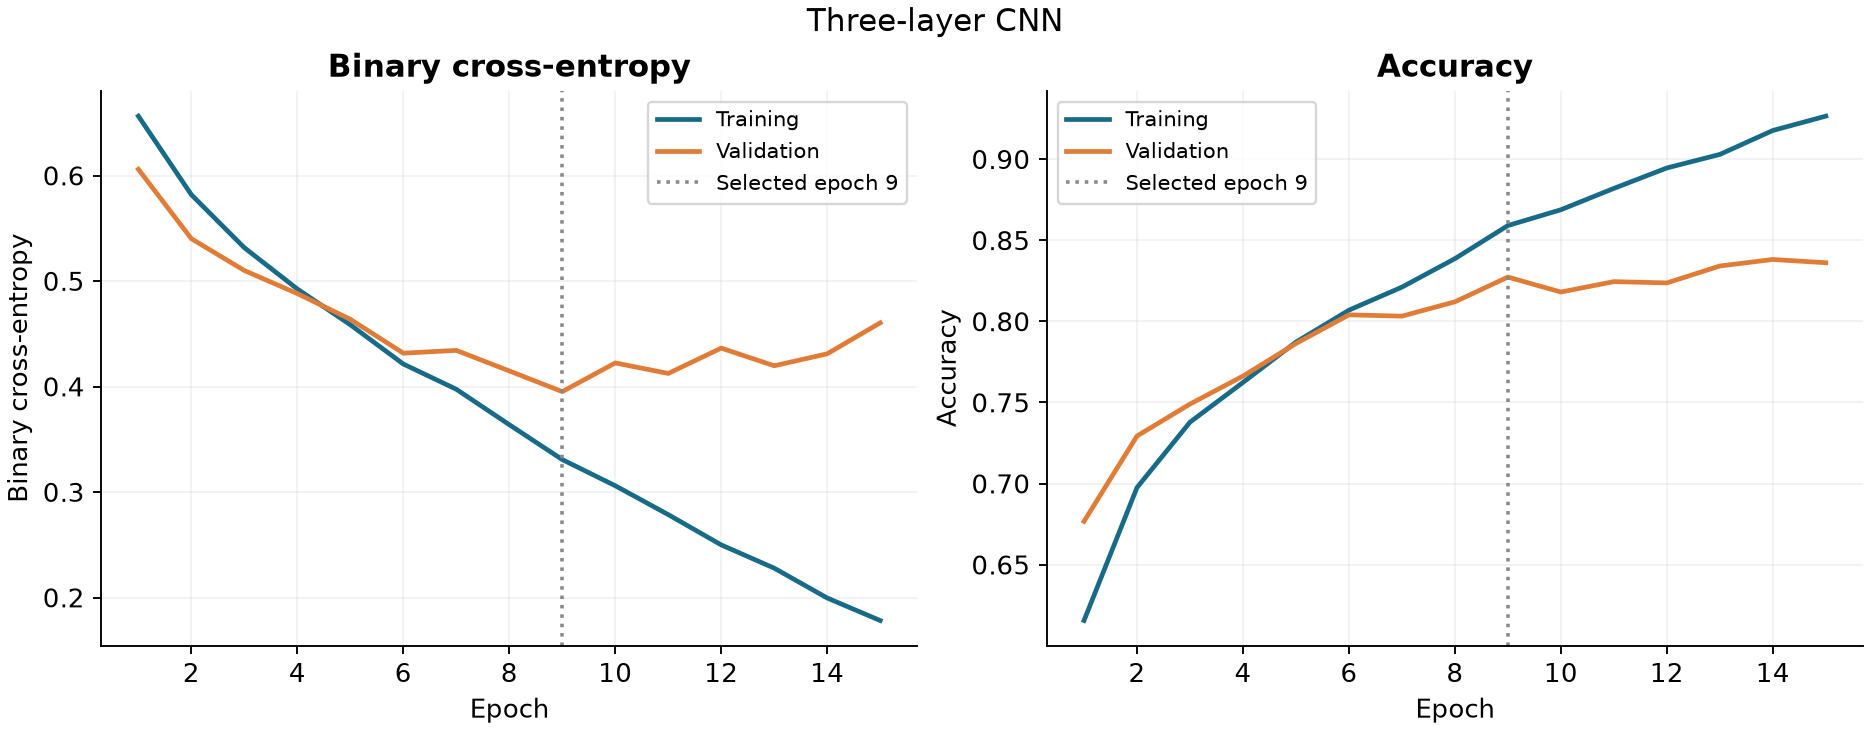

In [5]:
config = json.loads((ROOT/'results/cnn/config.json').read_text())
display(pd.read_csv(ROOT/'results/cnn/history.csv'))
display(DisplayImage(filename=str(ROOT/'figures/cnn_learning_curves.png')))

### Training and validation implementation
The engine switches between train/eval modes, clears gradients for each batch, uses
mixed precision on CUDA, clips gradient norms, and computes metrics over all examples.
Validation uses `inference_mode`; the last partial batch receives its correct weight.
Dropout makes training and validation metrics differ even without overfitting.
The saved histories are measurements, not illustrative or simulated curves.

In [6]:
print(inspect.getsource(train_run))

def train_run(name, epochs, seed=42, size=128, batch_size=64, workers=4, lr=None,
              data_root=None, run_name=None):
    seed_everything(seed)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    data_root = Path(data_root or ROOT / 'data' / 'Cats_and_Dogs')
    run_name = run_name or name
    output = ROOT / 'results' / run_name
    output.mkdir(parents=True, exist_ok=True)
    checkpoint_dir = ROOT / 'checkpoints'
    checkpoint_dir.mkdir(exist_ok=True)
    train_ds = datasets.ImageFolder(data_root / 'train', preprocessing(name, True, size))
    excluded = remove_training_duplicates(train_ds, data_root)
    val_ds = datasets.ImageFolder(data_root / 'val', preprocessing(name, False, size))
    assert train_ds.class_to_idx == val_ds.class_to_idx
    assert list(train_ds.class_to_idx.values()) == [0, 1]
    pretrained = name in ('vgg16', 'resnet18')
    model = build_model(name, pretrained=pretrained).to(device)
    actual_size = 150 if name == 'cnn' 

## 3. Part 2: transfer learning with VGG16 and ResNet18
Both feature extractors use torchvision's explicit `IMAGENET1K_V1` weights and their
official inference transforms: resize the shorter edge to 256, center-crop to 224,
scale pixels and normalize using ImageNet mean/std. The VGG head is the requested
512x7x7 -> 256 -> 1 architecture with ReLU and dropout 0.5. The ResNet head is
512 -> 256 -> 1 with the same activation/dropout.

The frozen backbones stay in eval mode, including ResNet BatchNorm. Deterministic
features are computed once, cached as float16, and promoted to float32 for head training.
This is mathematically the same frozen-feature workflow apart from float16 rounding;
it avoids repeatedly computing an unchanged backbone. Transfer training uses no random
augmentation. Only the new heads learn. VGG uses learning rate 0.0001 and ResNet 0.001.

In [7]:
class TransferModel(nn.Module):
    def __init__(self, architecture, pretrained=True):
        super().__init__()
        if architecture == 'vgg16':
            net = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None)
            self.features = nn.Sequential(net.features, nn.AdaptiveAvgPool2d((7, 7)), nn.Flatten())
            self.head = nn.Sequential(nn.Linear(512 * 7 * 7, 256), nn.ReLU(),
                                      nn.Dropout(0.5), nn.Linear(256, 1))
        elif architecture == 'resnet18':
            net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
            self.features = nn.Sequential(*list(net.children())[:-1], nn.Flatten())
            self.head = nn.Sequential(nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 1))
        else:
            raise ValueError(architecture)
        self.features.requires_grad_(False)

    def train(self, mode=True):
        super().train(mode)
        # Freezing parameters alone does not freeze ResNet's BatchNorm statistics.
        self.features.eval()
        return self

    def forward(self, x):
        with torch.no_grad():
            features = self.features(x)
        return self.head(features).squeeze(1)

,vgg16
name,vgg16
run_name,vgg16
epochs,15
seed,42
image_size,224
batch_size,64
class_to_idx,"{'cats': 0, 'dogs': 1}"
pretrained,True
train_images,19995
validation_images,2490


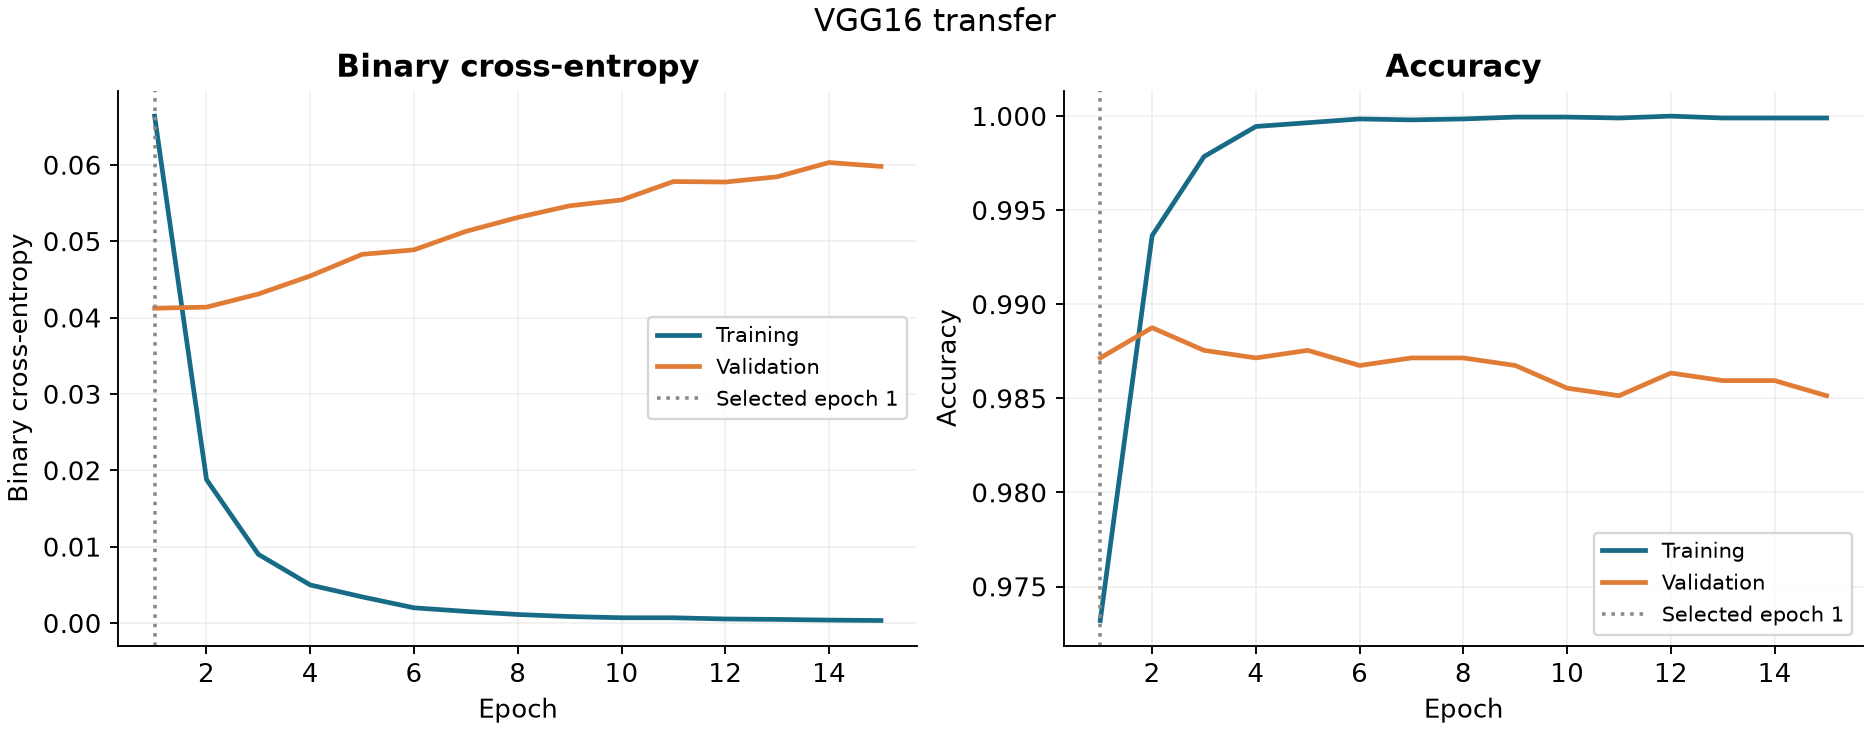

,resnet18
name,resnet18
run_name,resnet18
epochs,15
seed,42
image_size,224
batch_size,64
class_to_idx,"{'cats': 0, 'dogs': 1}"
pretrained,True
train_images,19995
validation_images,2490


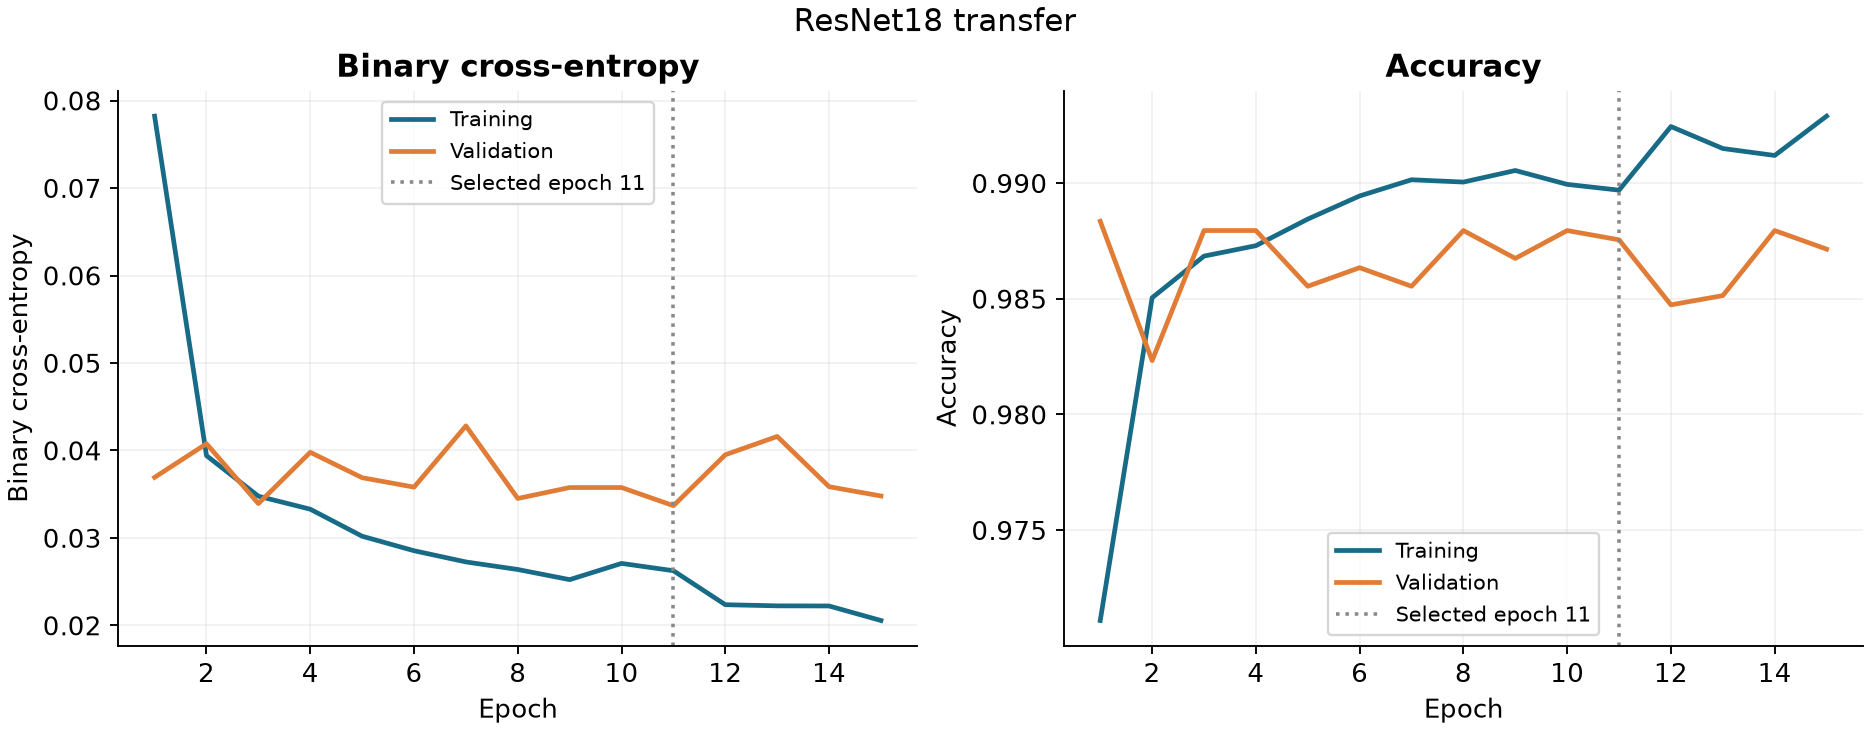

In [8]:
for name in ['vgg16','resnet18']:
    config = json.loads((ROOT/'results'/name/'config.json').read_text())
    display(pd.Series(config).to_frame(name))
    display(DisplayImage(filename=str(ROOT/'figures'/f'{name}_learning_curves.png')))

## 4. Part 3: contest model trained from scratch
The compact residual CNN below has no pretrained weights and uses no teacher,
pretrained feature cache, or pretrained ensemble member. Kaiming initialization and
residual connections support optimization. Training uses random resized crops,
horizontal flips, mild color jitter, dropout, AdamW weight decay 0.0001 and a cosine
learning-rate schedule. Normalization uses fixed mean/std 0.5, not fitted test statistics.

Label smoothing maps binary targets to 0.025 and 0.975 during training; validation and
test BCE always use hard labels. Thus the scratch model's training loss and validation
loss have different targets and should not be interpreted as a direct generalization gap.
Validation compares ordinary inference with averaging the original and horizontally
flipped logits; the lower validation BCE decides whether flip averaging is used.

In [9]:
class ResidualBlock(nn.Module):
    def __init__(self, inputs, outputs, stride=1):
        super().__init__()
        self.main = nn.Sequential(nn.Conv2d(inputs, outputs, 3, stride, 1, bias=False),
                                  nn.BatchNorm2d(outputs), nn.ReLU(),
                                  nn.Conv2d(outputs, outputs, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(outputs))
        self.skip = nn.Identity() if inputs == outputs and stride == 1 else nn.Sequential(
            nn.Conv2d(inputs, outputs, 1, stride, bias=False), nn.BatchNorm2d(outputs))

    def forward(self, x):
        return torch.relu(self.main(x) + self.skip(x))


class ScratchResNet(nn.Module):
    """Compact residual network: random initialization only; no external weights."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            ResidualBlock(32, 32), ResidualBlock(32, 64, 2),
            ResidualBlock(64, 128, 2), ResidualBlock(128, 128),
            ResidualBlock(128, 256, 2), ResidualBlock(256, 256),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(256, 1))
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

,Contest configuration
name,scratch
run_name,scratch
epochs,60
seed,42
image_size,128
batch_size,128
class_to_idx,"{'cats': 0, 'dogs': 1}"
pretrained,False
train_images,19995
validation_images,2490


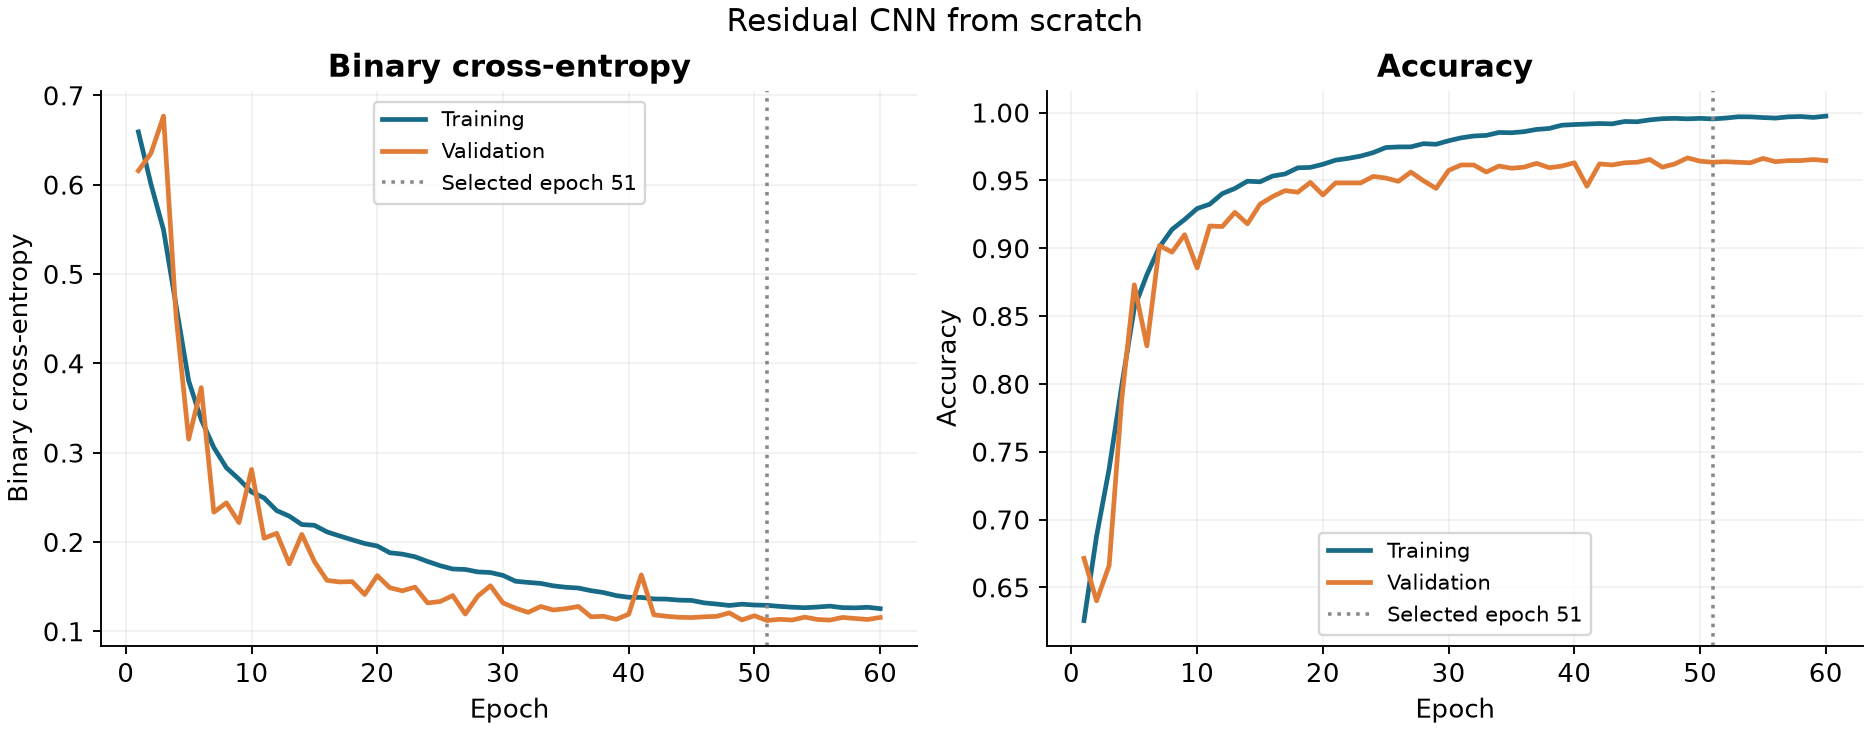

In [10]:
config = json.loads((ROOT/'results/scratch/config.json').read_text())
display(pd.Series(config).to_frame('Contest configuration'))
display(DisplayImage(filename=str(ROOT/'figures/scratch_learning_curves.png')))

## 5. Locked selection and final test evaluation
Test accuracy answers the required question; BCE measures probability quality,
ROC-AUC measures ranking, and F1 measures the dog-class precision/recall tradeoff.
Wilson intervals show uncertainty for each accuracy estimate and are not a paired
significance test. This is one seeded training run per architecture; it does not estimate
training-seed variability. ImageNet pretraining has a different data budget, so its
advantage must not be attributed solely to architecture.

,best_epoch,validation_accuracy,validation_loss,tta
cnn,9,0.827309,0.395155,False
resnet18,11,0.98755,0.033689,False
scratch,51,0.96988,0.102715,True
vgg16,1,0.987149,0.041229,False


,model,pretrained,best_epoch,accuracy,test_loss,roc_auc,tta
0,cnn,False,9,82.16%,0.3842,0.9077,False
1,resnet18,True,11,98.56%,0.0433,0.9986,False
2,scratch,False,51,96.32%,0.1137,0.9912,True
3,vgg16,True,1,98.32%,0.0481,0.9984,False


Best inference model, selected using validation BCE: resnet18


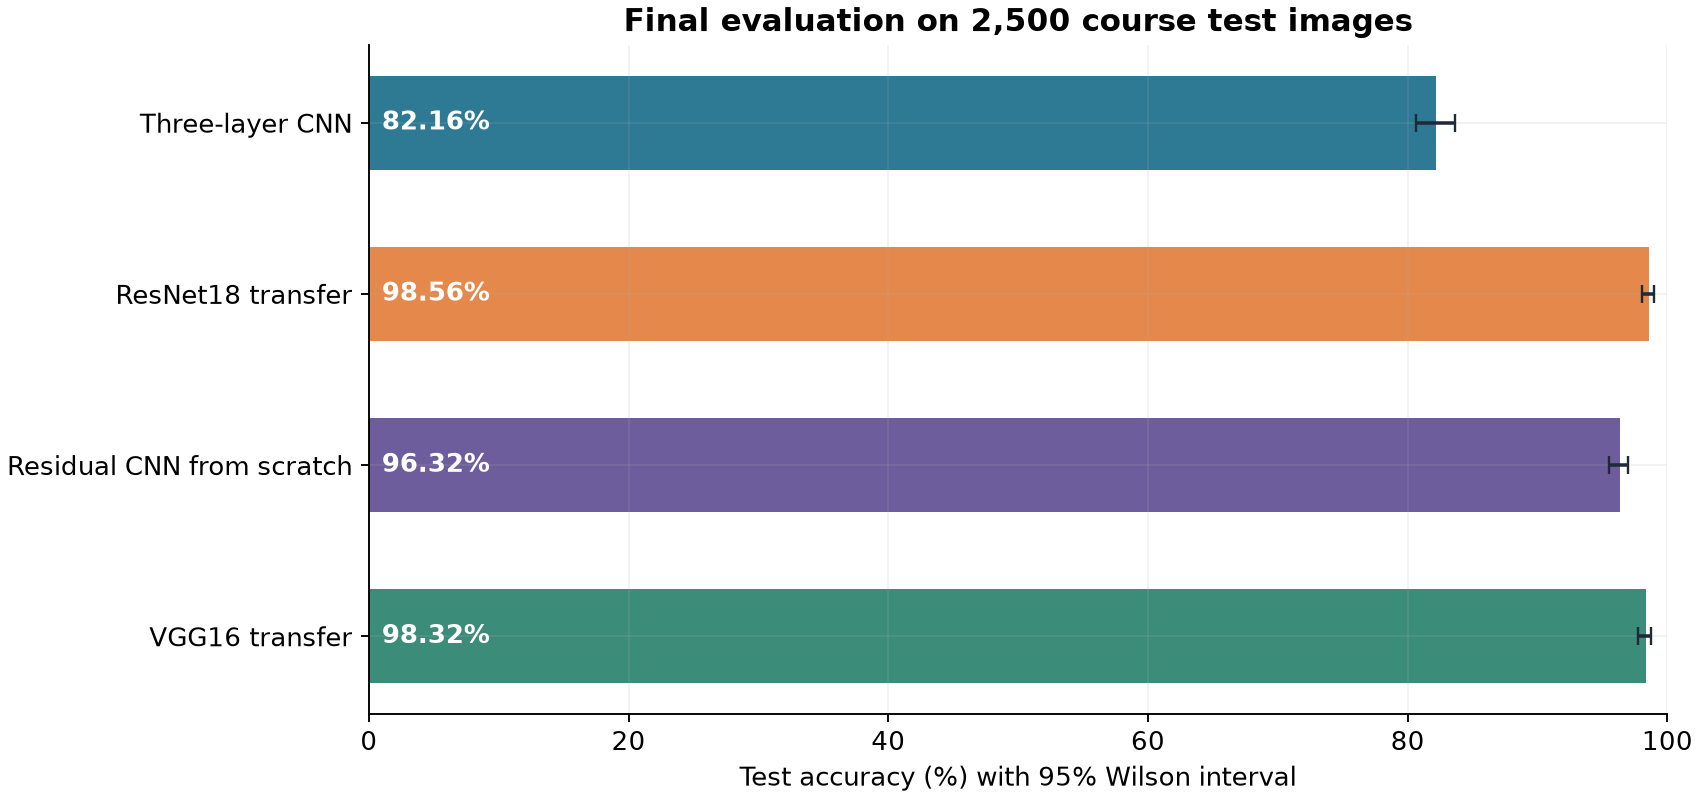

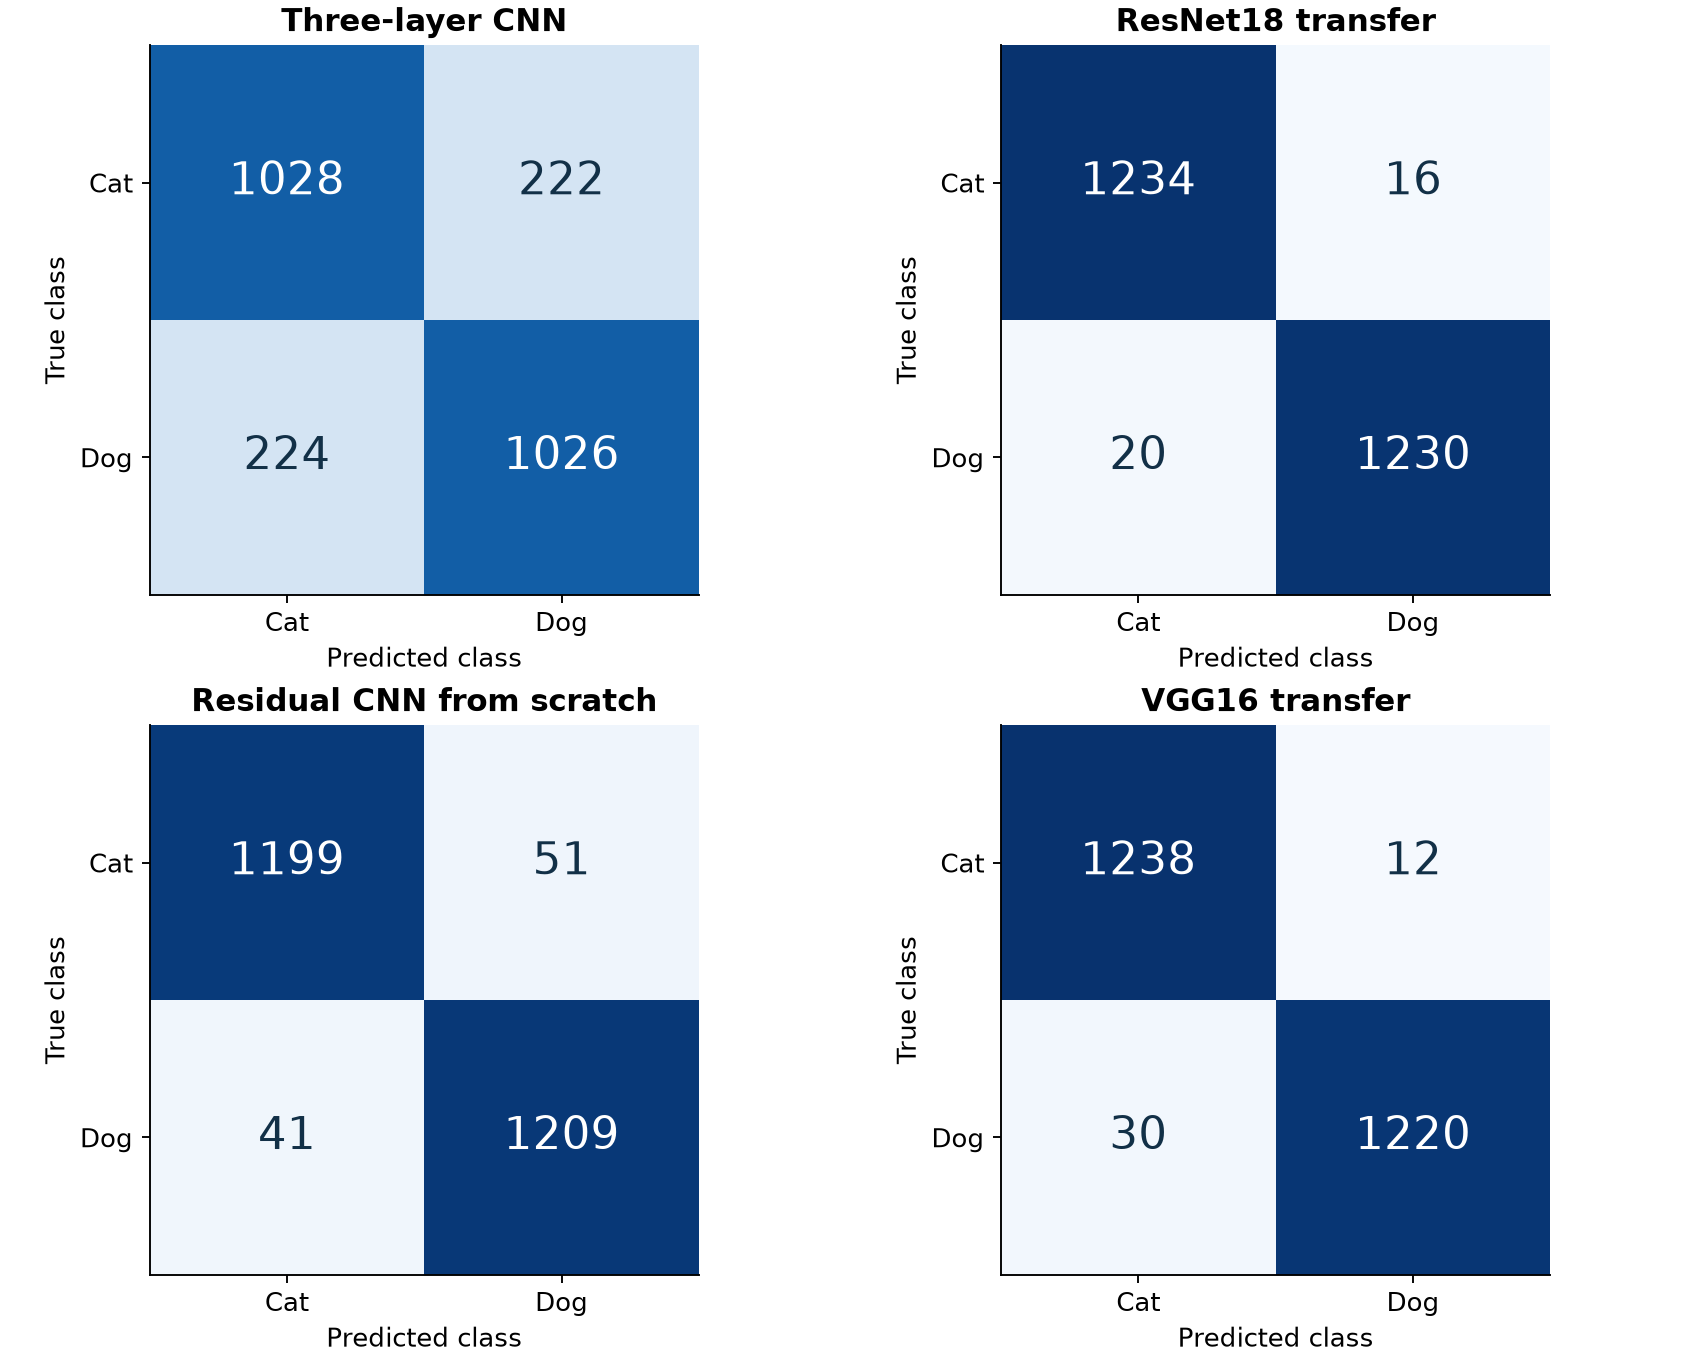

In [11]:
selection = json.loads((ROOT/'results/selection.json').read_text())
comparison = pd.read_csv(ROOT/'results/comparison.csv')
decisions = pd.DataFrame(selection['models']).T
display(decisions[['best_epoch','validation_accuracy','validation_loss','tta']])
display(comparison[['model','pretrained','best_epoch','accuracy','test_loss','roc_auc','tta']]
        .style.format({'accuracy':'{:.2%}', 'test_loss':'{:.4f}', 'roc_auc':'{:.4f}'}))
print('Best inference model, selected using validation BCE:', selection['best_inference_model'])
display(DisplayImage(filename=str(ROOT/'figures/model_comparison.png')))
display(DisplayImage(filename=str(ROOT/'figures/confusion_matrices.png')))

### Error analysis
The following are the most confident mistakes of the validation-selected model.
They help diagnose remaining limitations after evaluation; they were not used to
revise the fitted models. High sigmoid confidence is not proof of correctness or
calibrated probability. Cropping can remove context, and unusual poses/backgrounds
can differ from the training distribution. Several high-confidence errors shown here
contain both a cat and a dog, making the single dataset label ambiguous. Other examples
involve small subjects or poor lighting. The original labels were kept for scoring.

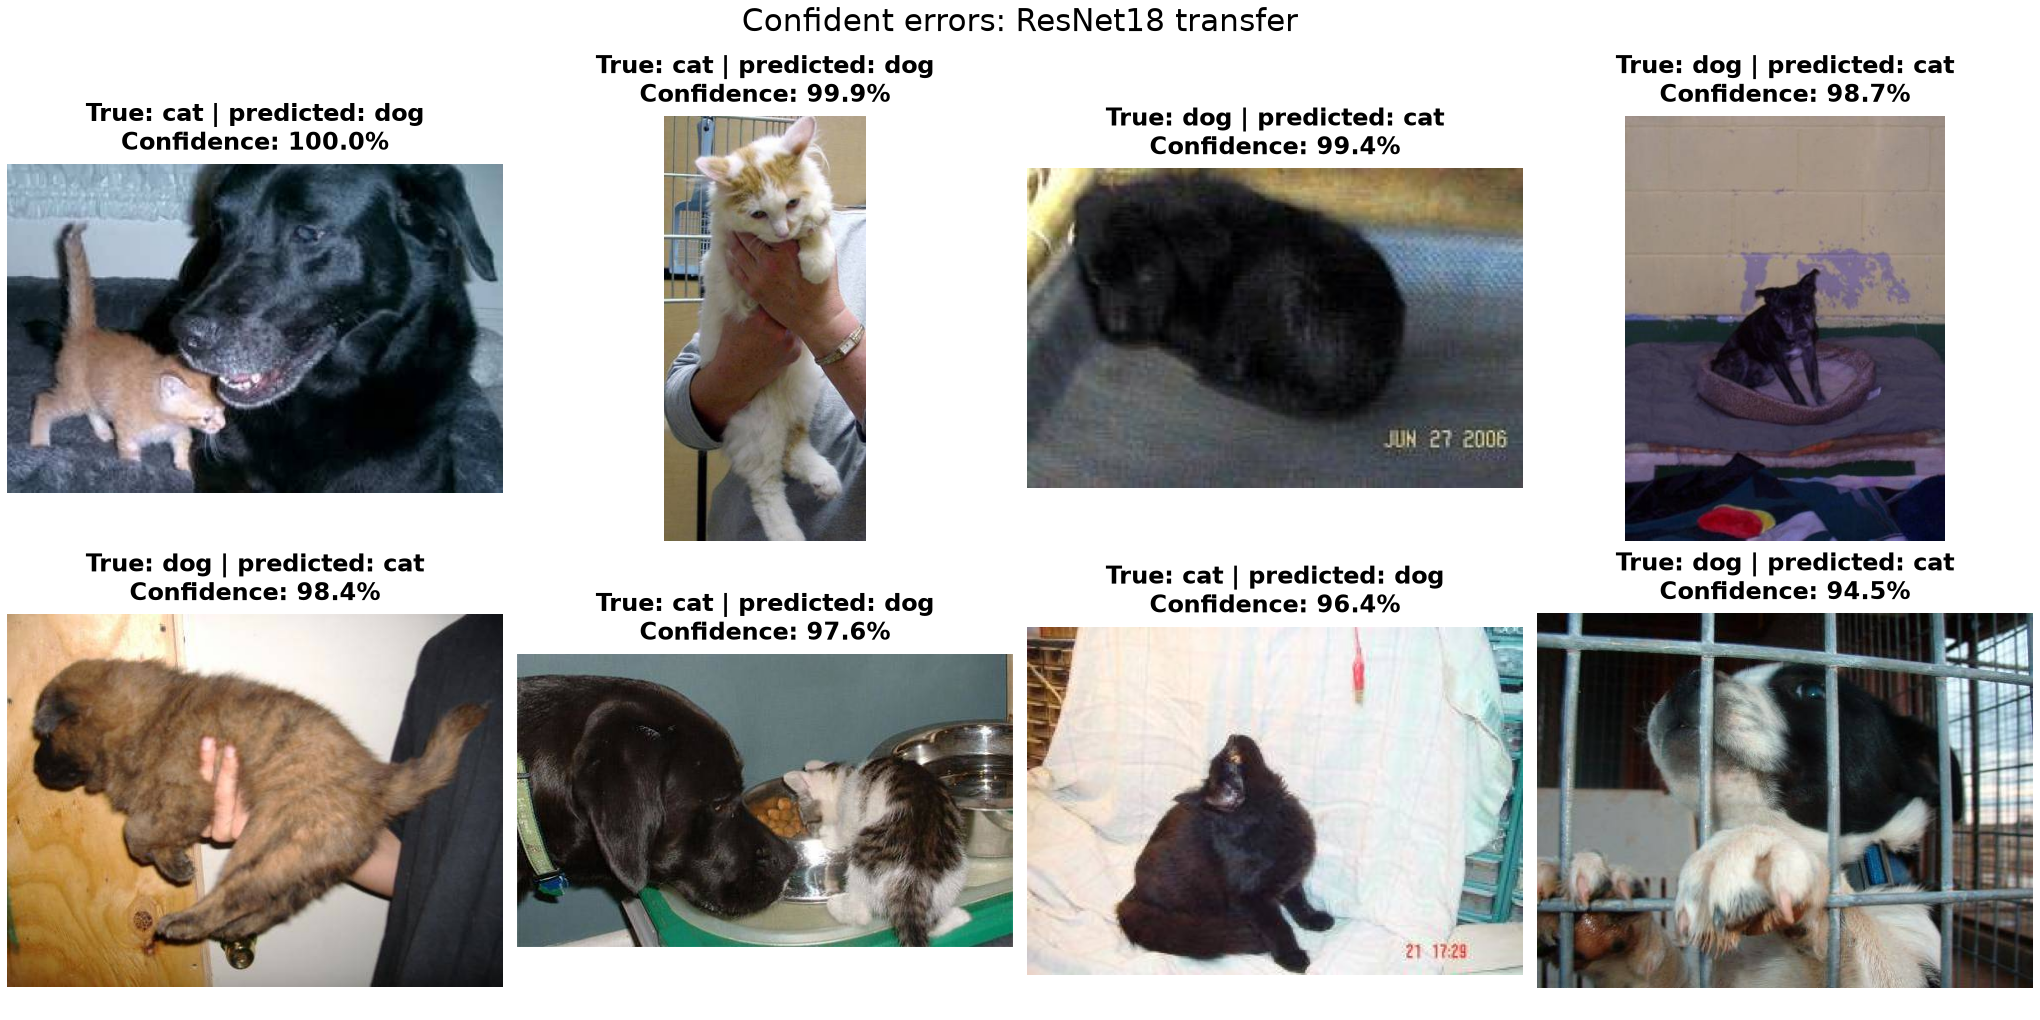

In [12]:
display(DisplayImage(filename=str(ROOT/'figures/error_analysis.png')))

## 6. Custom image and reusable inference
The example dog photograph comes from the PyTorch Hub repository, outside the course
archive. It is an inference demonstration, not another statistical test set; possible
overlap with ImageNet cannot be ruled out. Its source and hash are recorded in
`custom_images/README.md`. The function handles EXIF orientation and RGB conversion,
uses the checkpoint's class map, and returns both class probabilities.

@torch.inference_mode()
def predict_image(image_path, model, config, device, tta=False):
    """Return the class, both class probabilities and confidence (not calibration)."""
    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        x = preprocessing(config['name'], size=config['image_size'])(image).unsqueeze(0).to(device)
    model.eval()
    with amp(device):
        z = model(x)
        if tta:
            z = (z + model(x.flip(-1))) / 2
    p = z.float().sigmoid().item()
    names = {value: key for key, value in config['class_to_idx'].items()}
    index = int(p >= 0.5)
    return dict(predicted_class=names[index], confidence=p if index else 1 - p,
                probabilities={names[0]: 1 - p, names[1]: p})



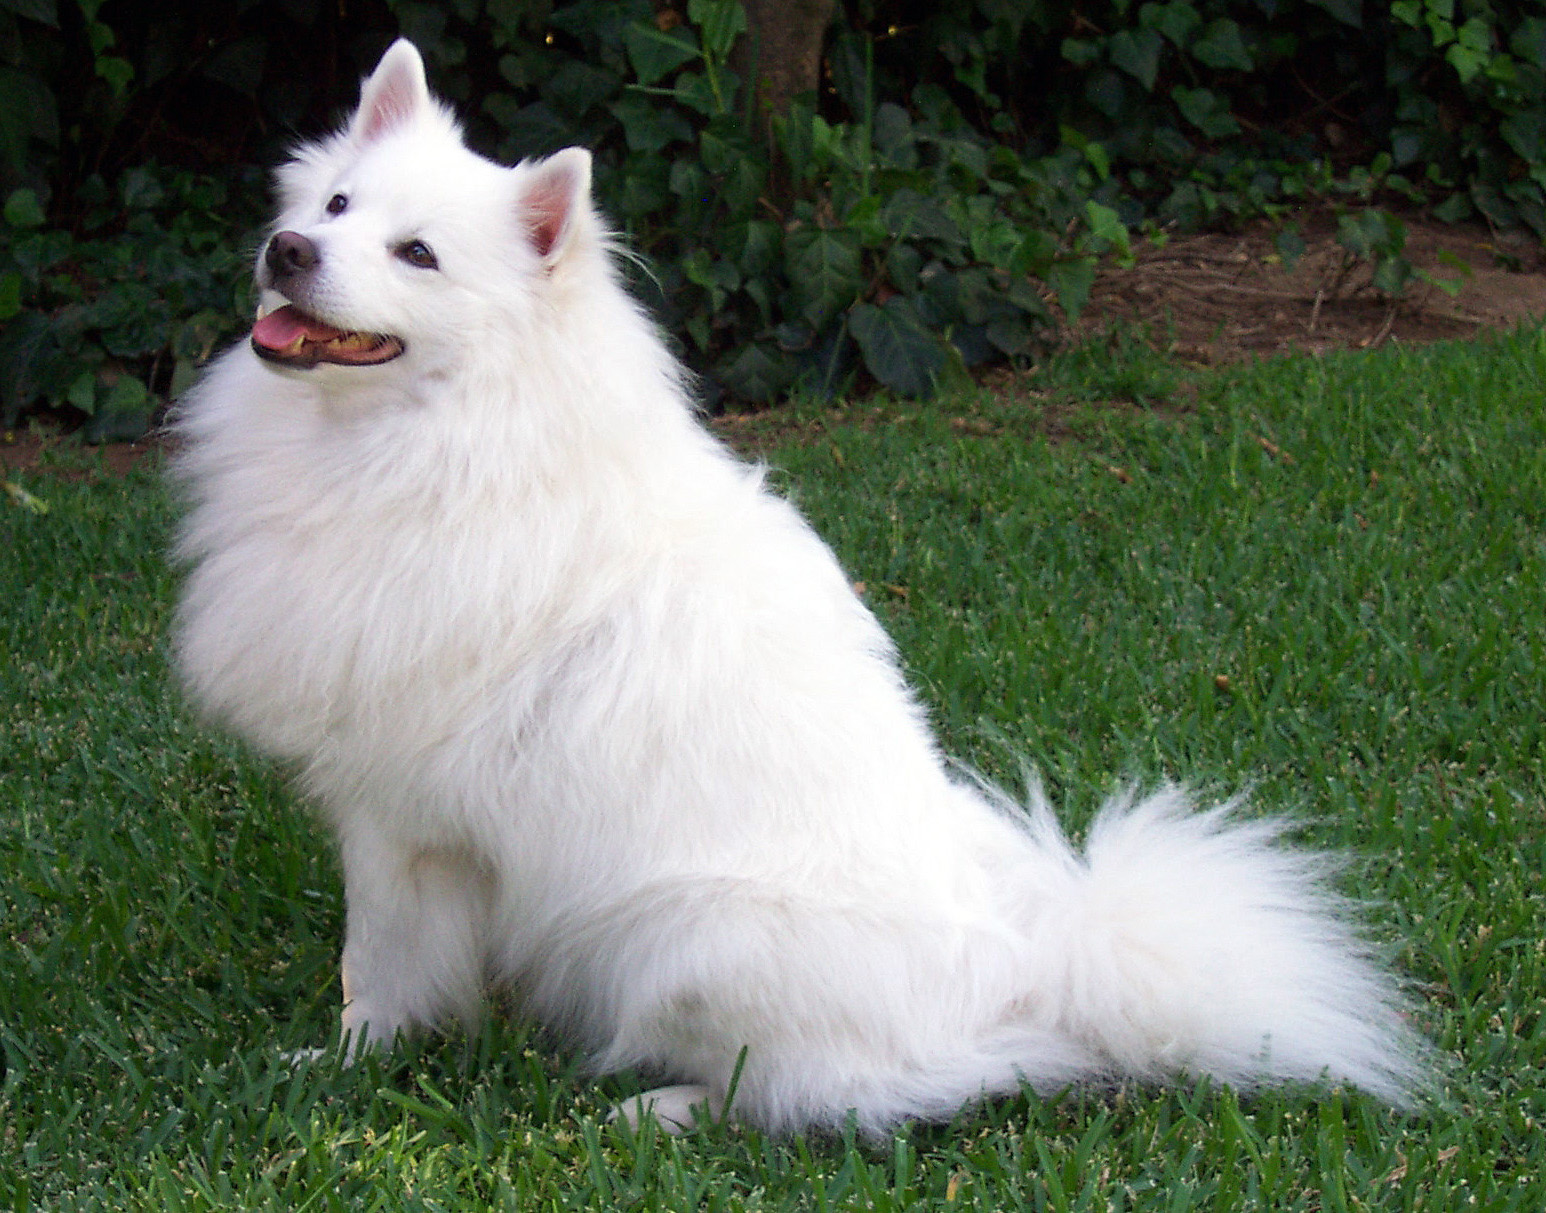

{
  "predicted_class": "dogs",
  "confidence": 0.8840392827987671,
  "probabilities": {
    "cats": 0.11596071720123291,
    "dogs": 0.8840392827987671
  }
}


In [13]:
print(inspect.getsource(predict_image))
best = selection['best_inference_model']
model, config, device = load_classifier(ROOT/'checkpoints'/f'{best}.pt')
result = predict_image(ROOT/'custom_images/dog.jpg', model, config, device,
                       tta=selection['models'][best]['tta'])
display(DisplayImage(filename=str(ROOT/'custom_images/dog.jpg'), width=400))
print(json.dumps(result, indent=2))
assert abs(sum(result['probabilities'].values()) - 1) < 1e-6
del model
torch.cuda.empty_cache()

## 7. Conclusions and reproducibility
The table and curves above separate the required baseline, transfer learning, and
the eligible contest model. Transfer learning can reuse features learned from a much
larger dataset; the scratch model must learn its own representation from 19,995 images.
The selected epoch may precede the final epoch because validation probability quality
can deteriorate even while training accuracy rises.

To reproduce: install `requirements.txt`, run `prepare_data.py`, and either set
`RUN_TRAINING=True` or run the training commands in README. Checkpoints are supplied
through the repository release and can also be regenerated. Saved metrics, histories,
predictions, configurations, data hashes and checkpoint hashes make the run auditable.
Fixed seeds improve repeatability; CUDA/kernel/library differences can still cause
numerical changes. The contest score is a measured result, not a guarantee of winning.

**References:** the supplied Task 4 PDF, Lecture 7 and PyTorch course notebook;
[torchvision models](https://docs.pytorch.org/vision/stable/models.html),
[VGG16](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html),
[ResNet18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).